# Proyecto 1 — Punto 3: fórmulas 1 a 4 de Kotriwar et al. (2018) y biespectro

Referencia: Kotriwar, Kachhara, Harikrishnan y Ambika, *Higher order spectral analysis of ECG signals*, arXiv:1809.08451.

Las cuatro fórmulas del artículo son:

1. Desviación por *detrending* polinomial, $\delta(n)$, para escoger el grado del polinomio.
2. Compresión (normalización min-máx) de la señal a $[0, 1]$.
3. Biespectro $b(f_1, f_2)$ promediado sobre $N$ segmentos.
4. Bicoherencia $B(f_1, f_2)$, el biespectro normalizado entre 0 y 1.

Se trabaja sobre la derivación II de los registros de `ECGDataDenoised` que están en el subconjunto del punto 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal

FS = 500                                   # Hz, Chapman-Shaoxing (10 s -> 5000 muestras)
RUTA_SENALES = Path("ECGDataDenoised")     # carpeta con los .csv de las señales (ajustar)
RUTA_SUBCONJUNTO = Path("subconjunto_punto2.csv")
DERIVACION_II = 1                          # columnas: I, II, III, aVR, aVL, aVF, V1..V6

In [2]:
def cargar_ecg(ruta_csv, derivacion=DERIVACION_II):
    # Siempre devuelve un vector 1-D (evita arrastrar formas viejas entre celdas)
    try:
        datos = pd.read_csv(ruta_csv, header=None).to_numpy(dtype=float)
    except ValueError:                     # por si el archivo trae encabezado
        datos = pd.read_csv(ruta_csv).to_numpy(dtype=float)
    x = np.asarray(datos[:, derivacion], dtype=float).ravel()
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        raise ValueError(f"Señal vacía, constante o con NaN: {ruta_csv}")
    return x

## Fórmula 1 — desviación por *detrending* polinomial

Se ajusta un polinomio de grado $n$ a la señal original $x^{(0)}$ y se resta, obteniendo la señal sin tendencia $x^{(n)}$. La desviación entre ambas es

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2$$

donde $k$ es la longitud de la señal. Se calcula para varios grados y se escoge el grado a partir del cual $\delta(n)$ se satura (los autores encontraron $n = 20$ en registros de 60 s).

**Cuidado al trasladarlo a Chapman.** Los registros duran 10 s, no 60 s. Un polinomio de grado alto en una ventana corta ya no solo sigue la deriva lenta: empieza a seguir la propia frecuencia cardíaca. Se comprobó con senoidales puras de 10 s a 500 Hz:

| Frecuencia | Grado 5 | Grado 10 | Grado 20 |
|---|---|---|---|
| 0.3 Hz (deriva) | 18 % | 97 % | 100 % |
| 0.5 Hz | 11 % | 30 % | 100 % |
| 1.0 Hz (pulso) | 4 % | 5 % | 27 % |
| 1.2 Hz | 3 % | 4 % | 14 % |

Esto es potencia eliminada por el ajuste. Con grado 20 se pierde más de una cuarta parte de la componente de 1 Hz, justo la frecuencia de pulso que se busca en el punto 4. Por eso aquí la curva $\delta(n)$ se usa para elegir el grado, pero con un tope de 10. Además, las señales de `ECGDataDenoised` ya pasaron por un LOESS que quitó la línea base, así que se espera una curva casi plana.

`np.polynomial.Polynomial.fit` reescala el eje temporal internamente; `np.polyfit` con grados altos sobre 5000 puntos es numéricamente inestable.

In [3]:
def detrend_polinomial(x, n):
    # Devuelve (señal sin tendencia, tendencia ajustada)
    t = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(t, x, deg=n)(t)
    return x - tendencia, tendencia


def delta_n(x, n):
    # Ec. (1): delta(n) = (1/k) * sum (x0(i) - xn(i))^2
    xn, _ = detrend_polinomial(x, n)
    return np.mean((x - xn) ** 2)


def curva_delta(x, grados=range(0, 21)):
    grados = np.array(list(grados))
    return grados, np.array([delta_n(x, n) for n in grados])


def elegir_grado(grados, deltas, tol=0.01, grado_max=10):
    # Primer grado en el que delta(n) cambia menos de tol (relativo) respecto al anterior, con tope
    cambio = np.abs(np.diff(deltas)) / np.maximum(deltas[1:], np.finfo(float).eps)
    estables = np.where(cambio < tol)[0]
    g = grados[estables[0] + 1] if len(estables) else grados[-1]
    return int(min(g, grado_max))

## Fórmula 2 — compresión

$$s(t_k) = \frac{x(t_k) - x_{\min}}{x_{\max} - x_{\min}}$$

Lleva todas las señales al intervalo $[0, 1]$ para compararlas sin sesgo por amplitud. Es la misma idea que el escalado min-máx de Zheng et al. (2020). La compresión no cambia la forma de la bicoherencia (que es adimensional), pero sí las potencias absolutas del espectro.

In [4]:
def compresion(x):
    # Ec. (2): s = (x - xmin) / (xmax - xmin)
    rango = np.max(x) - np.min(x)
    if rango == 0:
        raise ValueError("Señal constante: no se puede comprimir")
    return (x - np.min(x)) / rango

## Fórmulas 3 y 4 — biespectro y bicoherencia

La señal se divide en $N$ segmentos y se calcula la transformada de Fourier $X_j(f)$ de cada uno.

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2) \qquad \text{(3)}$$

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|} \qquad \text{(4)}$$

Por simetría basta la región $f_2 > 0$, $f_1 \ge f_2$, $f_1 + f_2 \le f_{\text{Nyquist}}$. Como el artículo, se calcula para $f_1, f_2 \le 20$ Hz, donde está casi toda la potencia del ECG.

**Elección de parámetros para registros de 10 s.** El artículo usó segmentos de 8192 muestras sobre 60 s a 1000 Hz; aquí eso es imposible. Hay un compromiso:

- El umbral de significancia es $\sqrt{9.2 / (2N)}$ y la bicoherencia de la ec. (4) nunca supera 1. Con $N < 5$ el umbral queda por encima de 1 y ningún par puede ser significativo. Con $N = 5$ (segmentos de 2 s) el umbral es 0.96, casi inalcanzable.
- Segmentos de 500 muestras (1 s) dan $N = 10$ y umbral 0.678, a costa de una resolución nativa de 1 Hz. Se rellena con ceros a `nfft = 1024` para tener una rejilla de 0.49 Hz (esto interpola el espectro, no mejora la resolución real).

Se usa ventana de Hann para reducir la fuga espectral (el artículo no especifica ventana; `ventana="boxcar"` reproduce la FFT sin ventana) y se quita la media de cada segmento para que la componente DC no domine.

In [5]:
def segmentar(x, nperseg, solape=0):
    paso = nperseg - solape
    n_seg = 1 + (len(x) - nperseg) // paso
    idx = np.arange(nperseg)[None, :] + paso * np.arange(n_seg)[:, None]
    return x[idx]                                   # (N, nperseg)


def fft_segmentos(x, fs=FS, nperseg=500, nfft=1024, ventana="hann"):
    seg = segmentar(np.asarray(x, dtype=float).ravel(), nperseg)
    seg = seg - seg.mean(axis=1, keepdims=True)
    w = signal.get_window(ventana, nperseg)
    X = np.fft.rfft(seg * w, n=nfft, axis=1)        # X_j(f) por segmento
    f = np.fft.rfftfreq(nfft, d=1 / fs)
    return f, X


def biespectro_bicoherencia(x, fs=FS, nperseg=500, nfft=1024, fmax=20, ventana="hann"):
    # Ec. (3) y (4). Devuelve f, b (complejo), B en [0,1], N y la máscara de la región no redundante
    f, X = fft_segmentos(x, fs, nperseg, nfft, ventana)
    N = X.shape[0]
    k = np.searchsorted(f, fmax, side="right")
    i = np.arange(k)
    K1, K2 = np.meshgrid(i, i, indexing="ij")              # K1 -> f1 (filas), K2 -> f2 (columnas)
    triple = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])   # (N, k, k)
    b = triple.sum(axis=0)                                  # ec. (3)
    denom = np.abs(triple).sum(axis=0)
    B = np.divide(np.abs(b), denom, out=np.zeros_like(denom), where=denom > 0)   # ec. (4)
    region = (K2 > 0) & (K1 >= K2)
    return f[:k], b, B, N, region


def umbral_bicoherencia(N):
    # N = número de SEGMENTOS promediados, no número de muestras
    return np.sqrt(9.2 / (2 * N))

## Validación con una señal sintética



Acoplada     B(5,3) = 1.000   umbral = 0.678
No acoplada  B(5,3) = 0.400   umbral = 0.678


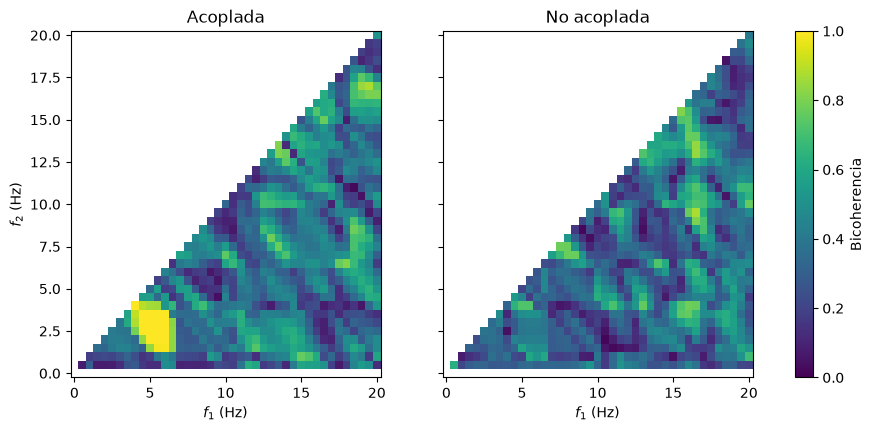

In [6]:
rng = np.random.default_rng(0)
t = np.arange(500) / FS

def sintetica(acoplada, n_seg=10):
    segs = []
    for _ in range(n_seg):
        p1, p2, p3 = rng.uniform(0, 2 * np.pi, 3)
        p3 = p1 + p2 if acoplada else p3
        segs.append(np.cos(2*np.pi*5*t + p1) + np.cos(2*np.pi*3*t + p2)
                    + np.cos(2*np.pi*8*t + p3) + 0.3 * rng.standard_normal(t.size))
    return np.concatenate(segs)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for eje, acoplada in zip(ejes, (True, False)):
    f, b, B, N, region = biespectro_bicoherencia(sintetica(acoplada), nfft=1000)
    i5, i3 = np.argmin(abs(f - 5)), np.argmin(abs(f - 3))
    print(f"{'Acoplada' if acoplada else 'No acoplada':12s} B(5,3) = {B[i5, i3]:.3f}   umbral = {umbral_bicoherencia(N):.3f}")
    im = eje.pcolormesh(f, f, np.where(region, B, np.nan).T, vmin=0, vmax=1, shading="auto")
    eje.set_title("Acoplada" if acoplada else "No acoplada")
    eje.set_xlabel("$f_1$ (Hz)")
ejes[0].set_ylabel("$f_2$ (Hz)")
fig.colorbar(im, ax=ejes, label="Bicoherencia")
plt.show()

In [7]:
rng_ruido = np.random.default_rng(1)
tasas = []
for _ in range(50):
    f, b, B, N, region = biespectro_bicoherencia(rng_ruido.standard_normal(5000))
    tasas.append((B[region] > umbral_bicoherencia(N)).mean())
print(f"Pares evaluados: {region.sum()}   Falsos positivos en ruido blanco: {100*np.mean(tasas):.1f} %"
      f"  (~{np.mean(tasas)*region.sum():.0f} pares por señal)")

Pares evaluados: 820   Falsos positivos en ruido blanco: 7.2 %  (~59 pares por señal)


## Aplicación a señales del subconjunto del punto 2

Se toma un registro al azar de cada ritmo del subconjunto y se aplica la cadena completa: curva $\delta(n)$ → *detrending* con el grado elegido → compresión → bicoherencia.

In [11]:
subconjunto = pd.read_csv(RUTA_SUBCONJUNTO)
print(subconjunto["Rhythm"].value_counts())

def procesar_registro(nombre, grados=range(0, 21)):
    x = cargar_ecg(RUTA_SENALES / f"{nombre}.csv")
    g, d = curva_delta(x, grados)
    n = elegir_grado(g, d)
    x_det, _ = detrend_polinomial(x, n)
    s = compresion(x_det)
    f, b, B, N, region = biespectro_bicoherencia(s)
    return dict(x=x, grados=g, deltas=d, n=n, s=s, f=f, b=b, B=B, N=N, region=region)

def primer_valido(grupo, semilla=42):
    for nombre in grupo.sample(frac=1, random_state=semilla)["FileName"]:
        try:
            return nombre, procesar_registro(nombre)
        except ValueError as e:
            print("  Se omite:", e)
    return None, None

resultados = {}
for ritmo, grupo in subconjunto.groupby("Rhythm"):
    nombre, r = primer_valido(grupo)
    if r is not None:
        resultados[ritmo] = r
        print(f"{ritmo}: {nombre}")

Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64
AFIB: MUSE_20180113_122043_40000
SB: MUSE_20180112_134027_79000
SR: MUSE_20180113_125854_77000
ST: MUSE_20180112_075431_42000
SVT: MUSE_20180712_151222_03000


In [14]:
"""cabe aclarar que si el archivo de algun 
paciente tiene valores faltantes o NaNel proceso se detiene"""
#ejemplo de un paciente que tenia valores faltantes 
ruta_mala = RUTA_SENALES / "MUSE_20181222_204131_50000.csv"
datos = pd.read_csv(ruta_mala, header=None).to_numpy(dtype=float)
print("Forma:", datos.shape)
print("NaN por derivación:", np.isnan(datos).sum(axis=0))
print("Rango por derivación:", np.round(np.nanmax(datos, axis=0) - np.nanmin(datos, axis=0), 2))

Forma: (5000, 12)
NaN por derivación: [0 0 0 0 0 0 0 0 0 0 0 0]
Rango por derivación: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


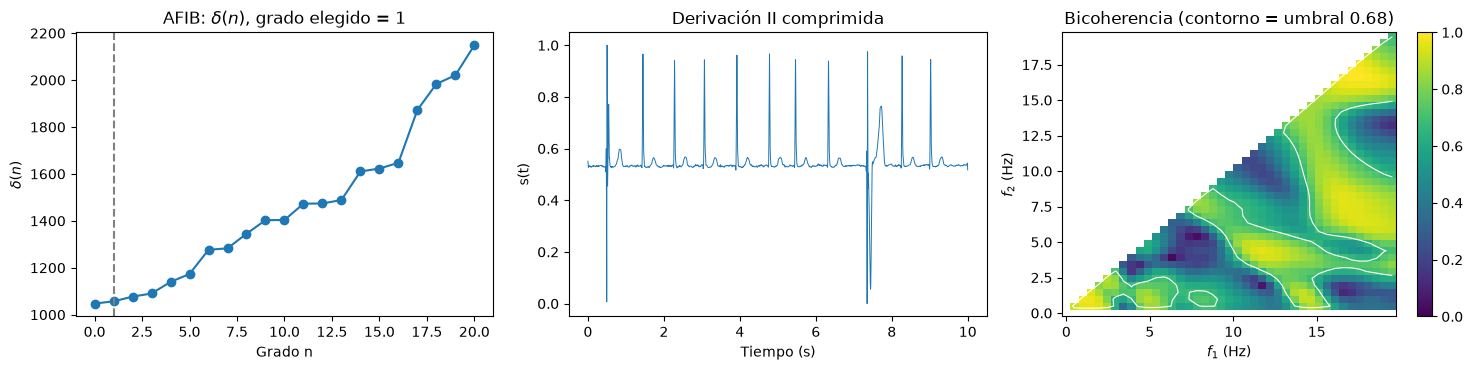

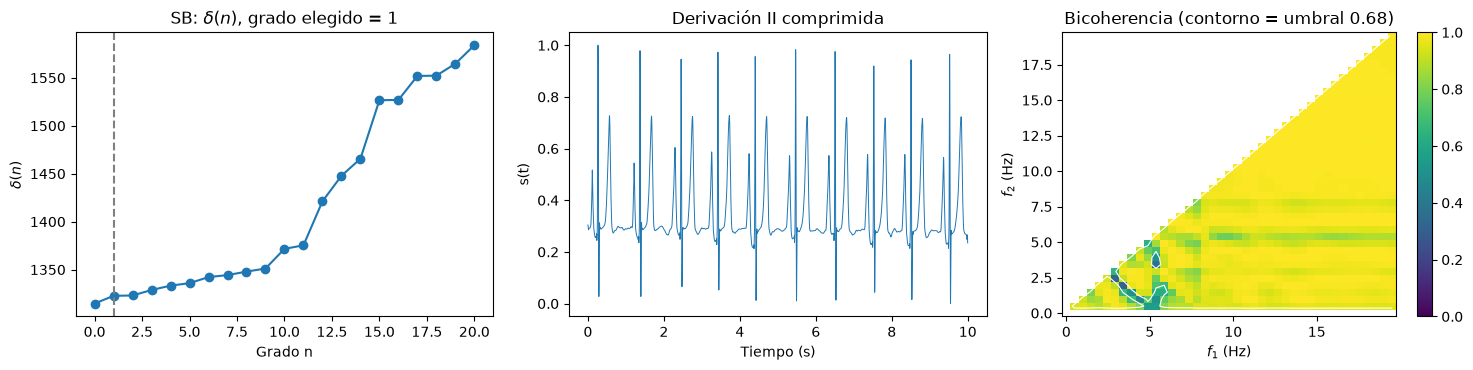

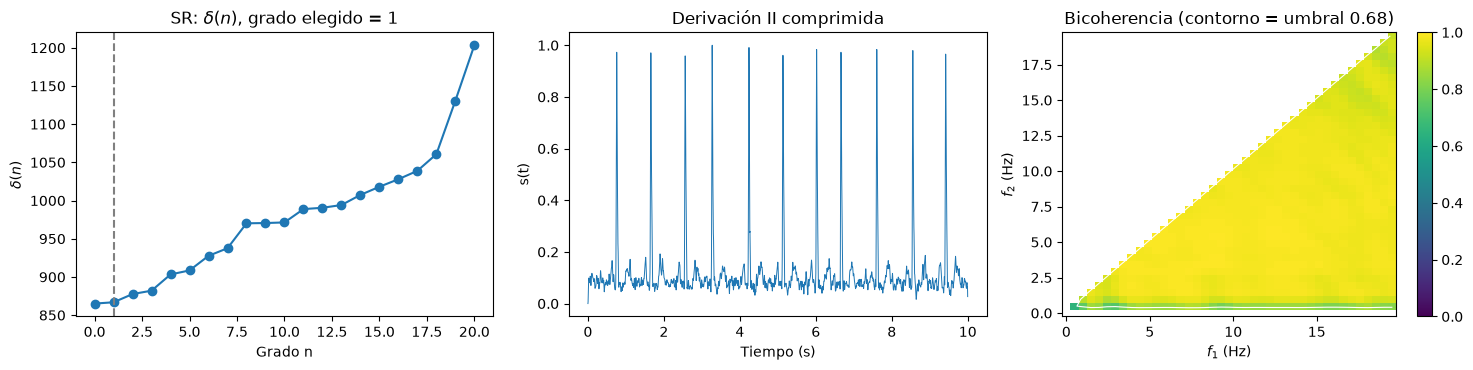

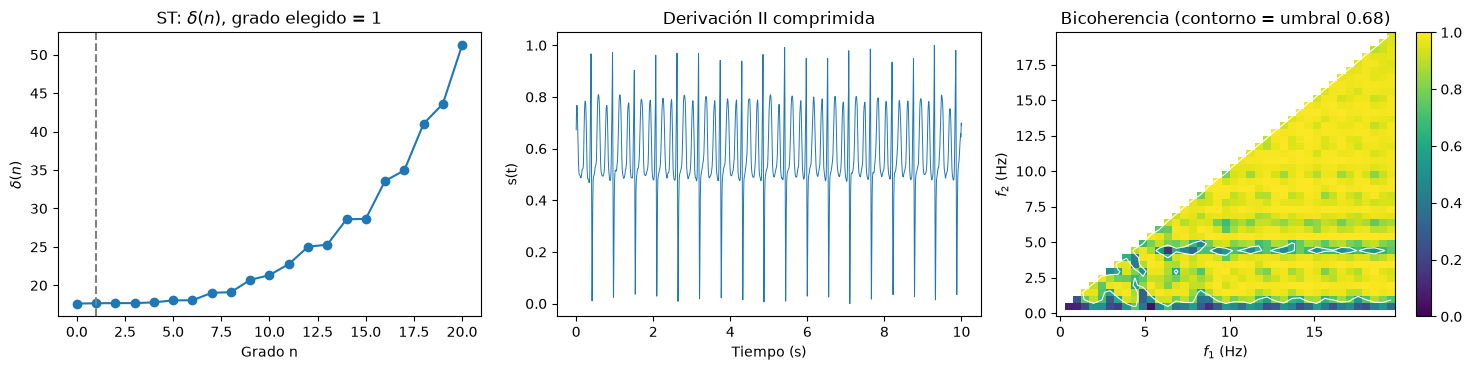

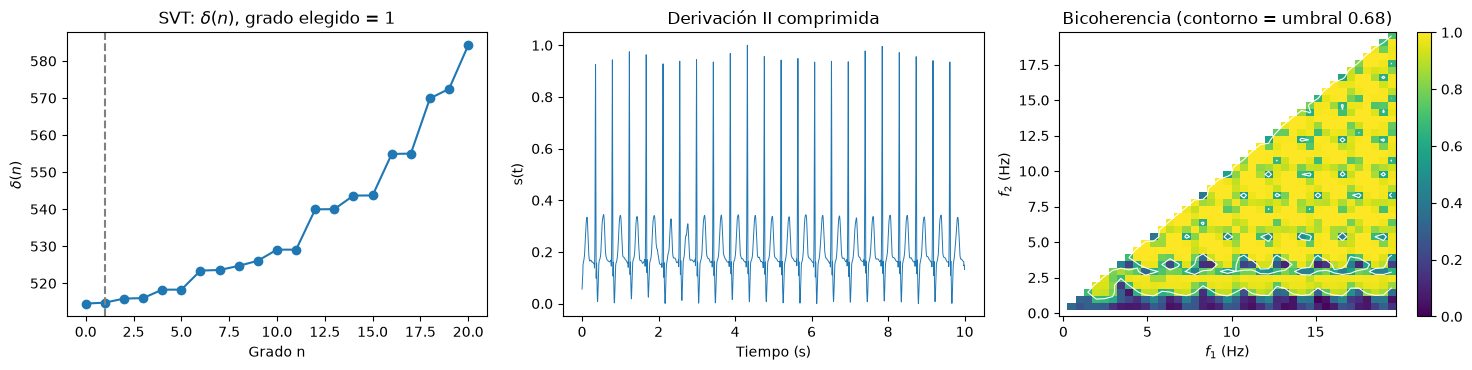

In [12]:
for ritmo, r in resultados.items():
    fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
    ejes[0].plot(r["grados"], r["deltas"], "o-")
    ejes[0].axvline(r["n"], ls="--", c="gray")
    ejes[0].set(title=f"{ritmo}: $\\delta(n)$, grado elegido = {r['n']}", xlabel="Grado n", ylabel="$\\delta(n)$")
    tt = np.arange(r["s"].size) / FS
    ejes[1].plot(tt, r["s"], lw=0.7)
    ejes[1].set(title="Derivación II comprimida", xlabel="Tiempo (s)", ylabel="s(t)")
    u = umbral_bicoherencia(r["N"])
    im = ejes[2].pcolormesh(r["f"], r["f"], np.where(r["region"], r["B"], np.nan).T, vmin=0, vmax=1, shading="auto")
    ejes[2].contour(r["f"], r["f"], np.where(r["region"], r["B"], 0).T, levels=[u], colors="w", linewidths=0.8)
    ejes[2].set(title=f"Bicoherencia (contorno = umbral {u:.2f})", xlabel="$f_1$ (Hz)", ylabel="$f_2$ (Hz)")
    fig.colorbar(im, ax=ejes[2])
    plt.tight_layout()
    plt.show()

## Significado y utilidad del biespectro

**Qué es.** El espectro de potencia es la transformada de Fourier de la autocorrelación (estadística de segundo orden): dice cuánta energía hay en cada frecuencia, pero descarta las fases. El biespectro es la transformada de Fourier de la correlación de tercer orden, $E[x(t)\,x(t+\tau_1)\,x(t+\tau_2)]$, y es una función de dos frecuencias. Su valor en $(f_1, f_2)$ es grande cuando existe una componente en $f_1 + f_2$ cuya fase está ligada a las de $f_1$ y $f_2$ ($\varphi_3 = \varphi_1 + \varphi_2$) de forma consistente entre segmentos. Eso se llama acoplamiento cuadrático de fase.

**Por qué importa.** Un sistema lineal no crea frecuencias nuevas: si entran $f_1$ y $f_2$, salen $f_1$ y $f_2$. Un sistema no lineal (por ejemplo, con un término cuadrático) genera $f_1 + f_2$ y $f_1 - f_2$ con fases amarradas a las originales. Por tanto, el biespectro distingue dos señales que tienen el mismo espectro de potencia: una cuyos picos son armónicos generados por la misma dinámica y otra cuyos picos son componentes independientes o ruido. Además, para un proceso gaussiano el biespectro es cero, así que también mide desviación de la gaussianidad.

**Bicoherencia.** El biespectro depende de la amplitud de la señal; la bicoherencia lo normaliza entre 0 (fases sin relación) y 1 (acoplamiento perfecto), lo que permite comparar registros y aplicar un umbral de significancia.

**Utilidad en ECG.** El latido produce una frecuencia fundamental (frecuencia de pulso, cerca de 1 Hz) y armónicos generados por la forma no sinusoidal del complejo P-QRS-T. En un corazón sano esos armónicos están acoplados en fase con el pulso. Kotriwar et al. encontraron que en sujetos sanos el pulso tiene acoplamiento significativo con muchas frecuencias, mientras que en patologías ese acoplamiento se pierde o aparecen frecuencias de potencia alta sin acoplamiento, que sugieren ruido o procesos estocásticos. En arritmias como la fibrilación auricular, donde la activación auricular es desorganizada y los intervalos RR son irregulares, se espera una estructura de bicoherencia distinta a la del ritmo sinusal. Esa diferencia es la que se cuantifica en los puntos 5 a 8. Otras aplicaciones del análisis biespectral incluyen EEG (por ejemplo, el índice biespectral de profundidad anestésica), detección de fallas en maquinaria y análisis de oleaje.